# Eye Disease Classification
**Course:** Deep Learning – Spring 2025/2026  
**Dataset:** Eye Diseases Classification (Kaggle)  
**Classes:** Cataract | Diabetic Retinopathy | Glaucoma | Normal  
**Task:** Image Classification using 4 CNN Architectures

## Step 1 – Mount Google Drive and Download Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Copy kaggle.json from your Drive
os.makedirs('/root/.config/kaggle', exist_ok=True)
os.system('cp /content/drive/MyDrive/kaggle.json /root/.config/kaggle/kaggle.json')
os.system('chmod 600 /root/.config/kaggle/kaggle.json')

# Download the dataset
os.system('kaggle datasets download -d gunavenkatdoddi/eye-diseases-classification')
os.system('unzip -q eye-diseases-classification.zip -d eye_disease')

print('Dataset downloaded!')
print(os.listdir('/content/eye_disease'))

Dataset downloaded!
['dataset']


## Step 2 – Import Libraries

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import copy, time, os

torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## Step 3 – Dataset Paths and Class Names

In [ ]:
# Update this path based on the extracted folder structure
import glob
# Find the folder that contains the class subfolders
for root, dirs, files in os.walk('/content/eye_disease'):
    if len(dirs) == 4:
        DATA_DIR = root
        print(f'Dataset folder found: {DATA_DIR}')
        print(f'Classes: {sorted(dirs)}')
        break

NUM_CLASSES = 4
CLASS_NAMES = sorted(os.listdir(DATA_DIR))
print(f'Class names: {CLASS_NAMES}')

Dataset folder found: /content/eye_disease/dataset
Classes: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
Class names: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


## Step 4 – Transforms and Data Loading
Resize to 224×224, convert to tensor, normalize — as used in Lab 5.

In [ ]:
# Standard transform — same for all architectures
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# Load full dataset using ImageFolder
full_dataset = ImageFolder(root=DATA_DIR, transform=transform)

print(f'Total images : {len(full_dataset)}')
print(f'Classes      : {full_dataset.classes}')

Total images : 4217
Classes      : ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


## Step 5 – Three-Way Data Split (L08)
70% train / 15% validation / 15% test

In [ ]:
total = len(full_dataset)
train_size = int(0.70 * total)
val_size   = int(0.15 * total)
test_size  = total - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size]
)

print(f'Train : {len(train_dataset)} images')
print(f'Val   : {len(val_dataset)} images')
print(f'Test  : {len(test_dataset)} images')

Train : 2951 images
Val   : 632 images
Test  : 634 images


## Step 6 – Data Loaders (Lab 5)

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f'Train batches: {len(train_loader)}')
print(f'Val batches  : {len(val_loader)}')
print(f'Test batches : {len(test_loader)}')

Train batches: 93
Val batches  : 20
Test batches : 20


## Step 7 – Visualise Sample Images

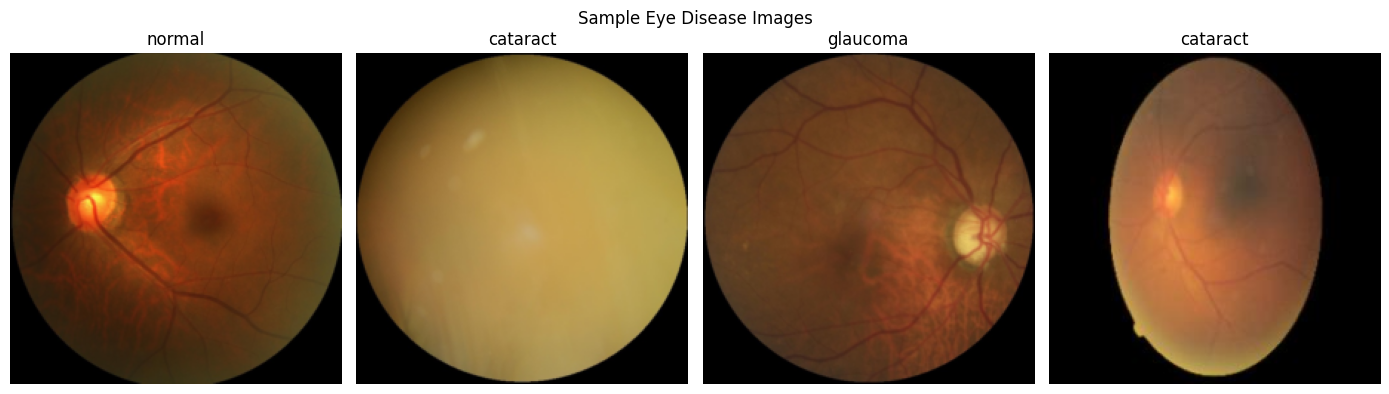

In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i in range(4):
    img = images[i].permute(1, 2, 0) * 0.5 + 0.5  # un-normalize
    axes[i].imshow(img.clamp(0, 1))
    axes[i].set_title(CLASS_NAMES[labels[i].item()])
    axes[i].axis('off')
plt.suptitle('Sample Eye Disease Images')
plt.tight_layout()
plt.show()

---
# Architecture Definitions

---
## Architecture 1 — Custom CNN (from scratch)
3 blocks: Conv2d → BatchNorm → ReLU → MaxPool. Dropout before FC. (L09, L10, L07)

In [ ]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=4, dropout_p=0.5):
        super(CustomCNN, self).__init__()

        self.relu    = nn.ReLU()
        self.pool    = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout = nn.Dropout(p=dropout_p)

        # Block 1
        self.conv1 = nn.Conv2d(3,  32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)

        # Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)

        # Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)

        # After 3 pools: 224 -> 112 -> 56 -> 28
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

print('Architecture 1 — Custom CNN defined.')

Architecture 1 — Custom CNN defined.


## Architecture 2 — Deeper CNN (from scratch)
4 blocks with 2 Conv layers per block. Inspired by VGGNet (L11).

In [ ]:
class DeeperCNN(nn.Module):
    def __init__(self, num_classes=4, dropout_p=0.5):
        super(DeeperCNN, self).__init__()

        self.relu    = nn.ReLU()
        self.pool    = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(p=dropout_p)

        # Block 1 — 2 conv layers
        self.conv1a = nn.Conv2d(3,   32,  kernel_size=3, padding=1)
        self.conv1b = nn.Conv2d(32,  32,  kernel_size=3, padding=1)
        self.bn1    = nn.BatchNorm2d(32)

        # Block 2
        self.conv2a = nn.Conv2d(32,  64,  kernel_size=3, padding=1)
        self.conv2b = nn.Conv2d(64,  64,  kernel_size=3, padding=1)
        self.bn2    = nn.BatchNorm2d(64)

        # Block 3
        self.conv3a = nn.Conv2d(64,  128, kernel_size=3, padding=1)
        self.conv3b = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn3    = nn.BatchNorm2d(128)

        # Block 4
        self.conv4a = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv4b = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.bn4    = nn.BatchNorm2d(256)

        # After 4 pools: 224 -> 14
        self.fc1 = nn.Linear(256 * 14 * 14, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1b(self.relu(self.conv1a(x))))))
        x = self.pool(self.relu(self.bn2(self.conv2b(self.relu(self.conv2a(x))))))
        x = self.pool(self.relu(self.bn3(self.conv3b(self.relu(self.conv3a(x))))))
        x = self.pool(self.relu(self.bn4(self.conv4b(self.relu(self.conv4a(x))))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

print('Architecture 2 — Deeper CNN defined.')

Architecture 2 — Deeper CNN defined.


## Architecture 3 — AlexNet (Pretrained on ImageNet)
Load pretrained AlexNet, freeze feature layers, replace classifier FC for 4 classes.

In [ ]:
def get_alexnet_pretrained(num_classes=4, dropout_p=0.5):
    """
    Load AlexNet with pretrained ImageNet weights.
    Replace the last FC layer to output num_classes.
    """
    model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)

    # Replace the final classifier layer
    # Original: nn.Linear(4096, 1000)
    # New: nn.Linear(4096, 4)
    model.classifier[6] = nn.Linear(4096, num_classes)

    return model

# Test it
test_model = get_alexnet_pretrained()
print('Architecture 3 — AlexNet pretrained defined.')
print(f'Final classifier layer: {test_model.classifier[6]}')
del test_model

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:00<00:00, 247MB/s]


Architecture 3 — AlexNet pretrained defined.
Final classifier layer: Linear(in_features=4096, out_features=4, bias=True)


## Architecture 4 — ResNet18 (from scratch, no pretrained weights)
Same ResNet18 architecture but trained from scratch on eye disease data.

In [ ]:
def get_resnet18_scratch(num_classes=4):
    """
    Load ResNet18 architecture with NO pretrained weights.
    Replace the final FC layer for num_classes.
    """
    model = models.resnet18(weights=None)  # no pretrained weights
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

test_model = get_resnet18_scratch()
print('Architecture 4 — ResNet18 from scratch defined.')
print(f'Final FC layer: {test_model.fc}')
del test_model

Architecture 4 — ResNet18 from scratch defined.
Final FC layer: Linear(in_features=512, out_features=4, bias=True)


---
# Training and Evaluation Functions
Same pattern as Lab 5.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    avg_loss = running_loss / len(loader)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc, all_labels, all_preds


def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs, device, model_name='Model'):
    model.to(device)
    train_losses, val_losses = [], []
    train_accs,   val_accs   = [], []

    print(f'\n--- Training {model_name} ---')
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)
        _, train_acc, _, _      = evaluate(model, train_loader, criterion, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f'Epoch [{epoch+1:02d}/{num_epochs}]  '
              f'Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}  '
              f'Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.4f}')

    return train_losses, val_losses, train_accs, val_accs


def plot_learning_curves(tl, vl, ta, va, model_name):
    epochs = range(1, len(tl) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, tl, label='Train Loss')
    axes[0].plot(epochs, vl, label='Val Loss')
    axes[0].set_title(f'{model_name} — Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[1].plot(epochs, ta, label='Train Accuracy')
    axes[1].plot(epochs, va, label='Val Accuracy')
    axes[1].set_title(f'{model_name} — Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()


def full_evaluation(model, loader, criterion, device, model_name):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc       = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall    = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1        = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm        = confusion_matrix(all_labels, all_preds)

    print(f'\n=== {model_name} — Test Results ===')
    print(f'  Accuracy  : {acc:.4f}')
    print(f'  Precision : {precision:.4f}')
    print(f'  Recall    : {recall:.4f}')
    print(f'  F1 Score  : {f1:.4f}')

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.colorbar()
    tick_marks = np.arange(NUM_CLASSES)
    plt.xticks(tick_marks, CLASS_NAMES, rotation=45)
    plt.yticks(tick_marks, CLASS_NAMES)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, str(cm[i, j]), ha='center', va='center', color='black')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

    return {'acc': acc, 'precision': precision, 'recall': recall, 'f1': f1, 'cm': cm}

print('All functions defined.')

All functions defined.


---
# Hyperparameter Combinations
3 combos per architecture × 4 architectures = 12 total experiments.

In [ ]:
criterion = nn.CrossEntropyLoss()

HP_COMBOS = [
    {'lr': 0.001,  'epochs': 10, 'dropout': 0.5, 'optimizer': 'Adam'},
    {'lr': 0.0001, 'epochs': 10, 'dropout': 0.5, 'optimizer': 'Adam'},
    {'lr': 0.001,  'epochs': 10, 'dropout': 0.3, 'optimizer': 'SGD'},
]

print('Hyperparameter combinations:')
for i, hp in enumerate(HP_COMBOS):
    print(f'  Combo {i+1}: {hp}')

Hyperparameter combinations:
  Combo 1: {'lr': 0.001, 'epochs': 10, 'dropout': 0.5, 'optimizer': 'Adam'}
  Combo 2: {'lr': 0.0001, 'epochs': 10, 'dropout': 0.5, 'optimizer': 'Adam'}
  Combo 3: {'lr': 0.001, 'epochs': 10, 'dropout': 0.3, 'optimizer': 'SGD'}


---
# Architecture 1 — Custom CNN Training


=== Architecture 1 — CustomCNN — Combo 1 ===
    lr=0.001, epochs=10, dropout=0.5, optimizer=Adam

--- Training CustomCNN Combo 1 ---
Epoch [01/10]  Train Loss: 4.4321  Train Acc: 0.5646  Val Loss: 0.9982  Val Acc: 0.5206
Epoch [02/10]  Train Loss: 1.0421  Train Acc: 0.5981  Val Loss: 0.8482  Val Acc: 0.5965
Epoch [03/10]  Train Loss: 0.9507  Train Acc: 0.6384  Val Loss: 0.8659  Val Acc: 0.5902
Epoch [04/10]  Train Loss: 0.9272  Train Acc: 0.5825  Val Loss: 0.8368  Val Acc: 0.5649
Epoch [05/10]  Train Loss: 0.9192  Train Acc: 0.6435  Val Loss: 0.7982  Val Acc: 0.6076
Epoch [06/10]  Train Loss: 0.9149  Train Acc: 0.5598  Val Loss: 0.8764  Val Acc: 0.5285
Epoch [07/10]  Train Loss: 0.9138  Train Acc: 0.6699  Val Loss: 0.7907  Val Acc: 0.6472
Epoch [08/10]  Train Loss: 0.8879  Train Acc: 0.6798  Val Loss: 0.7711  Val Acc: 0.6234
Epoch [09/10]  Train Loss: 0.8837  Train Acc: 0.5967  Val Loss: 0.8780  Val Acc: 0.5554
Epoch [10/10]  Train Loss: 0.8792  Train Acc: 0.6391  Val Loss: 0.7628  V

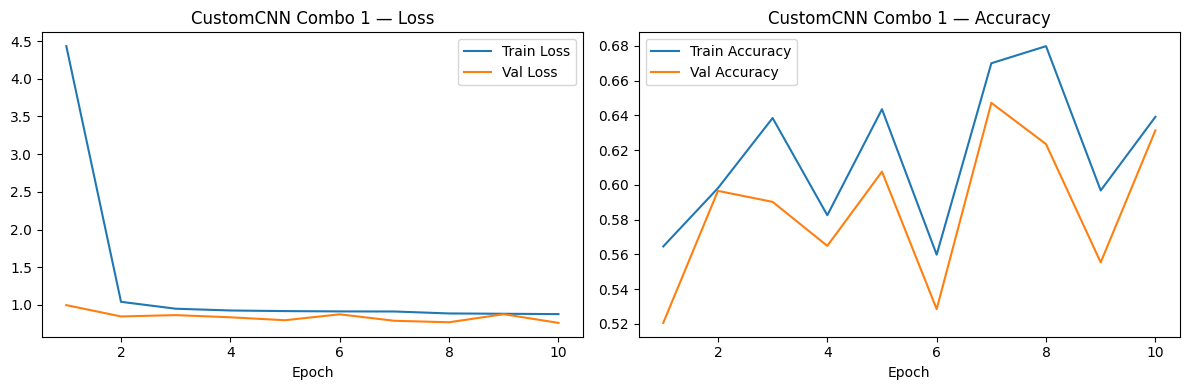


=== Architecture 1 — CustomCNN — Combo 2 ===
    lr=0.0001, epochs=10, dropout=0.5, optimizer=Adam

--- Training CustomCNN Combo 2 ---
Epoch [01/10]  Train Loss: 1.1024  Train Acc: 0.7245  Val Loss: 0.7223  Val Acc: 0.7009
Epoch [02/10]  Train Loss: 0.7387  Train Acc: 0.7841  Val Loss: 0.6368  Val Acc: 0.7500
Epoch [03/10]  Train Loss: 0.6454  Train Acc: 0.7994  Val Loss: 0.5628  Val Acc: 0.7595
Epoch [04/10]  Train Loss: 0.6118  Train Acc: 0.8282  Val Loss: 0.5522  Val Acc: 0.7753
Epoch [05/10]  Train Loss: 0.5654  Train Acc: 0.8506  Val Loss: 0.4978  Val Acc: 0.7975
Epoch [06/10]  Train Loss: 0.5108  Train Acc: 0.8584  Val Loss: 0.4743  Val Acc: 0.8117
Epoch [07/10]  Train Loss: 0.4937  Train Acc: 0.8800  Val Loss: 0.4293  Val Acc: 0.8307
Epoch [08/10]  Train Loss: 0.4481  Train Acc: 0.8905  Val Loss: 0.4345  Val Acc: 0.8259
Epoch [09/10]  Train Loss: 0.4300  Train Acc: 0.8905  Val Loss: 0.4035  Val Acc: 0.8339
Epoch [10/10]  Train Loss: 0.3905  Train Acc: 0.8834  Val Loss: 0.4520  

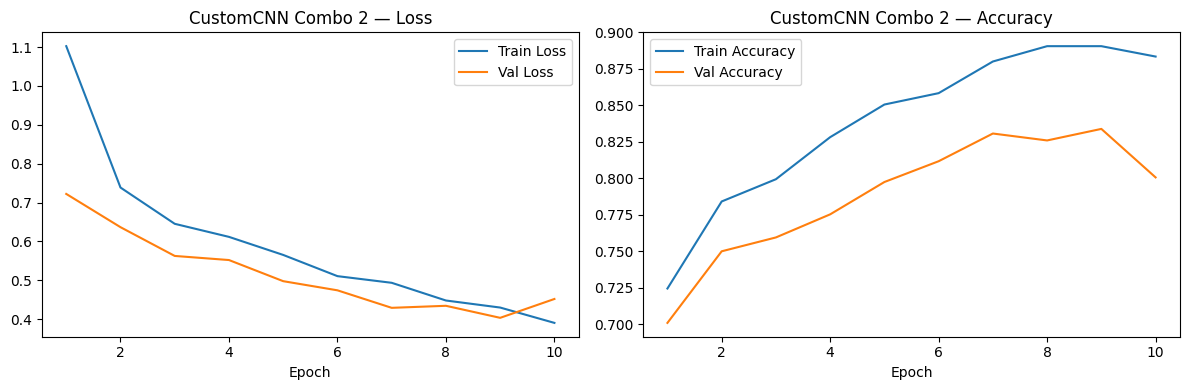


=== Architecture 1 — CustomCNN — Combo 3 ===
    lr=0.001, epochs=10, dropout=0.3, optimizer=SGD

--- Training CustomCNN Combo 3 ---
Epoch [01/10]  Train Loss: 0.9153  Train Acc: 0.6930  Val Loss: 0.7388  Val Acc: 0.6725
Epoch [02/10]  Train Loss: 0.6765  Train Acc: 0.7645  Val Loss: 0.6087  Val Acc: 0.7247
Epoch [03/10]  Train Loss: 0.6030  Train Acc: 0.7645  Val Loss: 0.6067  Val Acc: 0.7437
Epoch [04/10]  Train Loss: 0.5804  Train Acc: 0.7831  Val Loss: 0.5905  Val Acc: 0.7421
Epoch [05/10]  Train Loss: 0.5154  Train Acc: 0.8153  Val Loss: 0.4944  Val Acc: 0.7943
Epoch [06/10]  Train Loss: 0.4835  Train Acc: 0.8428  Val Loss: 0.4907  Val Acc: 0.7880
Epoch [07/10]  Train Loss: 0.4369  Train Acc: 0.8163  Val Loss: 0.5182  Val Acc: 0.7706
Epoch [08/10]  Train Loss: 0.4464  Train Acc: 0.8712  Val Loss: 0.4707  Val Acc: 0.8085
Epoch [09/10]  Train Loss: 0.4053  Train Acc: 0.8502  Val Loss: 0.4638  Val Acc: 0.8038
Epoch [10/10]  Train Loss: 0.3834  Train Acc: 0.8526  Val Loss: 0.5060  Va

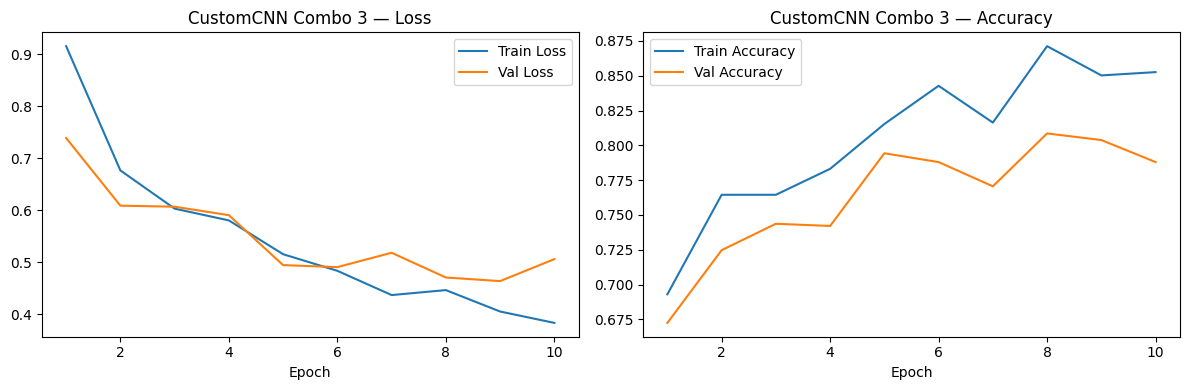


Best combo for Architecture 1: Combo 2 — Val Acc: 0.8339


In [ ]:
arch1_results = []

for i, hp in enumerate(HP_COMBOS):
    print(f'\n=== Architecture 1 — CustomCNN — Combo {i+1} ===')
    print(f'    lr={hp["lr"]}, epochs={hp["epochs"]}, dropout={hp["dropout"]}, optimizer={hp["optimizer"]}')

    model = CustomCNN(num_classes=NUM_CLASSES, dropout_p=hp['dropout']).to(device)

    if hp['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=hp['lr'])
    else:
        optimizer = optim.SGD(model.parameters(), lr=hp['lr'], momentum=0.9)

    tl, vl, ta, va = train_model(model, train_loader, val_loader,
                                  criterion, optimizer, hp['epochs'],
                                  device, f'CustomCNN Combo {i+1}')

    plot_learning_curves(tl, vl, ta, va, f'CustomCNN Combo {i+1}')

    arch1_results.append({'combo': i+1, 'hp': hp, 'model': model,
                           'best_val_acc': max(va)})

best_arch1 = max(arch1_results, key=lambda x: x['best_val_acc'])
print(f'\nBest combo for Architecture 1: Combo {best_arch1["combo"]} — Val Acc: {best_arch1["best_val_acc"]:.4f}')

---
# Architecture 2 — Deeper CNN Training


=== Architecture 2 — DeeperCNN — Combo 1 ===
    lr=0.001, epochs=10, dropout=0.5, optimizer=Adam

--- Training DeeperCNN Combo 1 ---
Epoch [01/10]  Train Loss: 4.5249  Train Acc: 0.3589  Val Loss: 1.6601  Val Acc: 0.3465
Epoch [02/10]  Train Loss: 1.4426  Train Acc: 0.4114  Val Loss: 1.3043  Val Acc: 0.3956
Epoch [03/10]  Train Loss: 1.3027  Train Acc: 0.4775  Val Loss: 1.1922  Val Acc: 0.4668
Epoch [04/10]  Train Loss: 1.2091  Train Acc: 0.5361  Val Loss: 1.1118  Val Acc: 0.5047
Epoch [05/10]  Train Loss: 1.1859  Train Acc: 0.5324  Val Loss: 1.0887  Val Acc: 0.5095
Epoch [06/10]  Train Loss: 1.1278  Train Acc: 0.5944  Val Loss: 0.9659  Val Acc: 0.5665
Epoch [07/10]  Train Loss: 1.0730  Train Acc: 0.6069  Val Loss: 0.9220  Val Acc: 0.5918
Epoch [08/10]  Train Loss: 0.9925  Train Acc: 0.6530  Val Loss: 0.8399  Val Acc: 0.6092
Epoch [09/10]  Train Loss: 0.9288  Train Acc: 0.6442  Val Loss: 0.8588  Val Acc: 0.6250
Epoch [10/10]  Train Loss: 0.9349  Train Acc: 0.6723  Val Loss: 0.8103  V

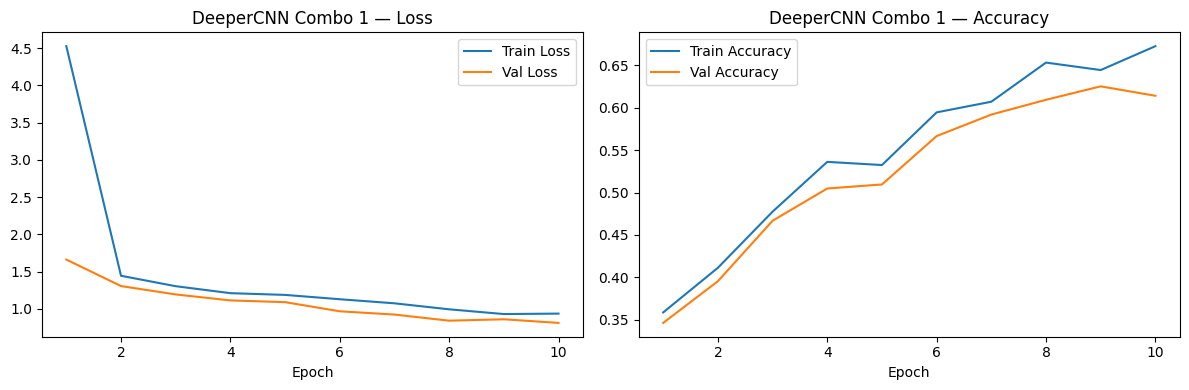


=== Architecture 2 — DeeperCNN — Combo 2 ===
    lr=0.0001, epochs=10, dropout=0.5, optimizer=Adam

--- Training DeeperCNN Combo 2 ---
Epoch [01/10]  Train Loss: 1.2667  Train Acc: 0.6645  Val Loss: 0.8522  Val Acc: 0.6250
Epoch [02/10]  Train Loss: 0.7124  Train Acc: 0.7841  Val Loss: 0.6131  Val Acc: 0.7326
Epoch [03/10]  Train Loss: 0.5704  Train Acc: 0.8174  Val Loss: 0.4969  Val Acc: 0.7991
Epoch [04/10]  Train Loss: 0.5079  Train Acc: 0.8136  Val Loss: 0.5346  Val Acc: 0.7848
Epoch [05/10]  Train Loss: 0.4576  Train Acc: 0.8611  Val Loss: 0.4423  Val Acc: 0.8149
Epoch [06/10]  Train Loss: 0.4261  Train Acc: 0.8638  Val Loss: 0.4192  Val Acc: 0.8101
Epoch [07/10]  Train Loss: 0.3909  Train Acc: 0.8909  Val Loss: 0.4043  Val Acc: 0.8449
Epoch [08/10]  Train Loss: 0.3426  Train Acc: 0.8936  Val Loss: 0.4148  Val Acc: 0.8228
Epoch [09/10]  Train Loss: 0.3242  Train Acc: 0.9000  Val Loss: 0.3798  Val Acc: 0.8370
Epoch [10/10]  Train Loss: 0.3055  Train Acc: 0.9234  Val Loss: 0.3573  

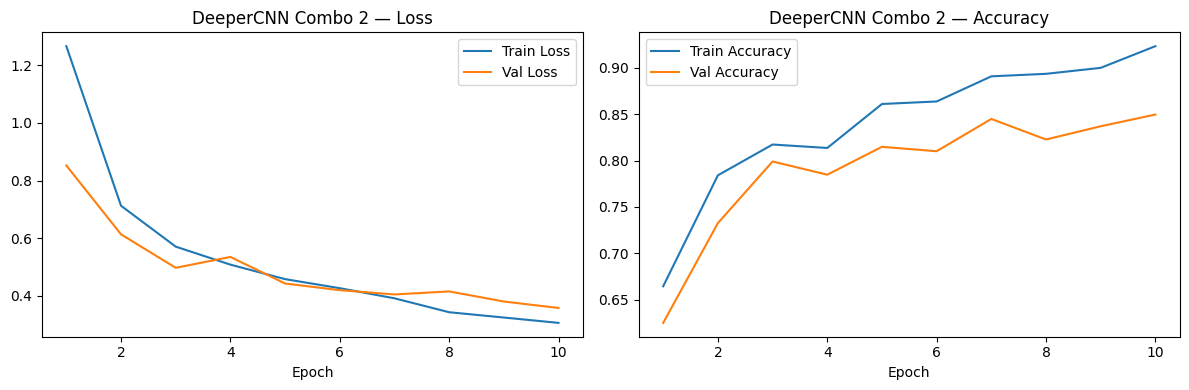


=== Architecture 2 — DeeperCNN — Combo 3 ===
    lr=0.001, epochs=10, dropout=0.3, optimizer=SGD

--- Training DeeperCNN Combo 3 ---
Epoch [01/10]  Train Loss: 0.9146  Train Acc: 0.7116  Val Loss: 0.7182  Val Acc: 0.6804
Epoch [02/10]  Train Loss: 0.6289  Train Acc: 0.7885  Val Loss: 0.5495  Val Acc: 0.7500
Epoch [03/10]  Train Loss: 0.5298  Train Acc: 0.7838  Val Loss: 0.5935  Val Acc: 0.7547
Epoch [04/10]  Train Loss: 0.4511  Train Acc: 0.7943  Val Loss: 0.5783  Val Acc: 0.7611
Epoch [05/10]  Train Loss: 0.4117  Train Acc: 0.8573  Val Loss: 0.4399  Val Acc: 0.8180
Epoch [06/10]  Train Loss: 0.3802  Train Acc: 0.8729  Val Loss: 0.4044  Val Acc: 0.8354
Epoch [07/10]  Train Loss: 0.3311  Train Acc: 0.8855  Val Loss: 0.3690  Val Acc: 0.8323
Epoch [08/10]  Train Loss: 0.3436  Train Acc: 0.9031  Val Loss: 0.3392  Val Acc: 0.8608
Epoch [09/10]  Train Loss: 0.2836  Train Acc: 0.9214  Val Loss: 0.3237  Val Acc: 0.8655
Epoch [10/10]  Train Loss: 0.2750  Train Acc: 0.8983  Val Loss: 0.4000  Va

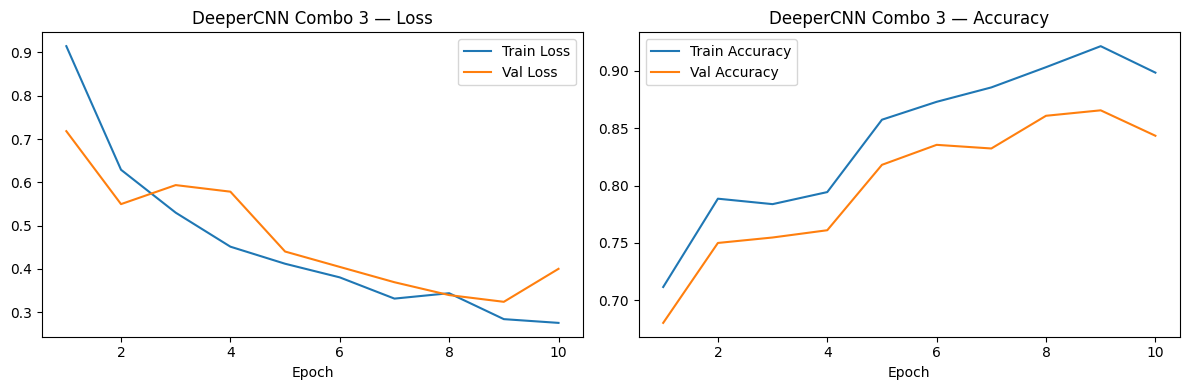


Best combo for Architecture 2: Combo 3 — Val Acc: 0.8655


In [ ]:
arch2_results = []

for i, hp in enumerate(HP_COMBOS):
    print(f'\n=== Architecture 2 — DeeperCNN — Combo {i+1} ===')
    print(f'    lr={hp["lr"]}, epochs={hp["epochs"]}, dropout={hp["dropout"]}, optimizer={hp["optimizer"]}')

    model = DeeperCNN(num_classes=NUM_CLASSES, dropout_p=hp['dropout']).to(device)

    if hp['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=hp['lr'])
    else:
        optimizer = optim.SGD(model.parameters(), lr=hp['lr'], momentum=0.9)

    tl, vl, ta, va = train_model(model, train_loader, val_loader,
                                  criterion, optimizer, hp['epochs'],
                                  device, f'DeeperCNN Combo {i+1}')

    plot_learning_curves(tl, vl, ta, va, f'DeeperCNN Combo {i+1}')

    arch2_results.append({'combo': i+1, 'hp': hp, 'model': model,
                           'best_val_acc': max(va)})

best_arch2 = max(arch2_results, key=lambda x: x['best_val_acc'])
print(f'\nBest combo for Architecture 2: Combo {best_arch2["combo"]} — Val Acc: {best_arch2["best_val_acc"]:.4f}')

---
# Architecture 3 — AlexNet Pretrained Training
Uses ImageNet pretrained weights. Fine-tunes only the final classifier layer.


=== Architecture 3 — AlexNet Pretrained — Combo 1 ===
    lr=0.001, epochs=10, optimizer=Adam

--- Training AlexNet Pretrained Combo 1 ---
Epoch [01/10]  Train Loss: 0.7715  Train Acc: 0.7536  Val Loss: 0.5996  Val Acc: 0.7516
Epoch [02/10]  Train Loss: 0.6427  Train Acc: 0.7204  Val Loss: 0.6513  Val Acc: 0.7358
Epoch [03/10]  Train Loss: 0.6073  Train Acc: 0.7889  Val Loss: 0.5059  Val Acc: 0.7975
Epoch [04/10]  Train Loss: 0.5850  Train Acc: 0.8177  Val Loss: 0.4670  Val Acc: 0.8101
Epoch [05/10]  Train Loss: 0.5510  Train Acc: 0.7296  Val Loss: 0.6887  Val Acc: 0.7168
Epoch [06/10]  Train Loss: 0.5843  Train Acc: 0.8323  Val Loss: 0.4448  Val Acc: 0.8133
Epoch [07/10]  Train Loss: 0.5661  Train Acc: 0.8245  Val Loss: 0.4561  Val Acc: 0.7975
Epoch [08/10]  Train Loss: 0.5606  Train Acc: 0.7987  Val Loss: 0.4954  Val Acc: 0.7880
Epoch [09/10]  Train Loss: 0.5328  Train Acc: 0.8546  Val Loss: 0.4272  Val Acc: 0.8196
Epoch [10/10]  Train Loss: 0.5321  Train Acc: 0.7699  Val Loss: 0.59

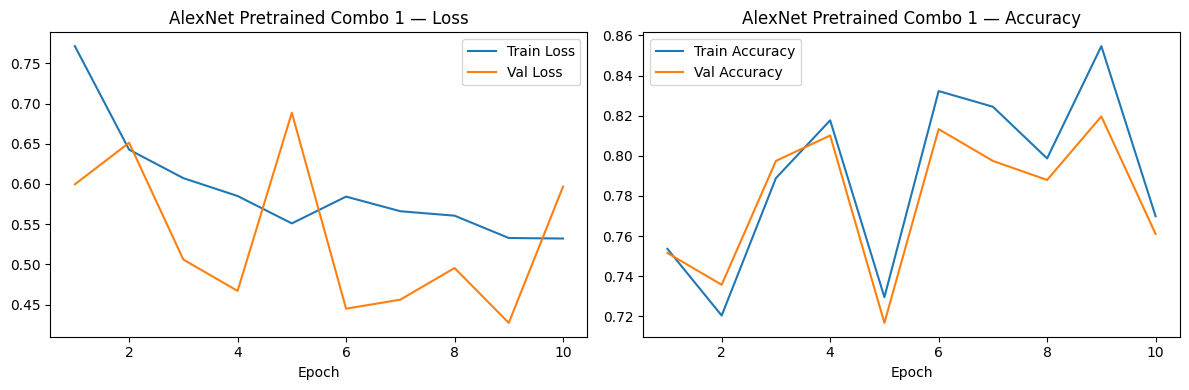


=== Architecture 3 — AlexNet Pretrained — Combo 2 ===
    lr=0.0001, epochs=10, optimizer=Adam

--- Training AlexNet Pretrained Combo 2 ---
Epoch [01/10]  Train Loss: 0.9945  Train Acc: 0.7015  Val Loss: 0.7702  Val Acc: 0.7152
Epoch [02/10]  Train Loss: 0.7694  Train Acc: 0.7425  Val Loss: 0.6784  Val Acc: 0.7358
Epoch [03/10]  Train Loss: 0.7226  Train Acc: 0.7174  Val Loss: 0.6722  Val Acc: 0.7278
Epoch [04/10]  Train Loss: 0.6828  Train Acc: 0.7584  Val Loss: 0.6075  Val Acc: 0.7595
Epoch [05/10]  Train Loss: 0.6563  Train Acc: 0.7604  Val Loss: 0.5847  Val Acc: 0.7674
Epoch [06/10]  Train Loss: 0.6366  Train Acc: 0.7675  Val Loss: 0.5723  Val Acc: 0.7690
Epoch [07/10]  Train Loss: 0.6212  Train Acc: 0.7770  Val Loss: 0.5625  Val Acc: 0.7690
Epoch [08/10]  Train Loss: 0.6137  Train Acc: 0.7801  Val Loss: 0.5400  Val Acc: 0.7801
Epoch [09/10]  Train Loss: 0.6142  Train Acc: 0.7872  Val Loss: 0.5324  Val Acc: 0.7816
Epoch [10/10]  Train Loss: 0.5942  Train Acc: 0.7791  Val Loss: 0.5

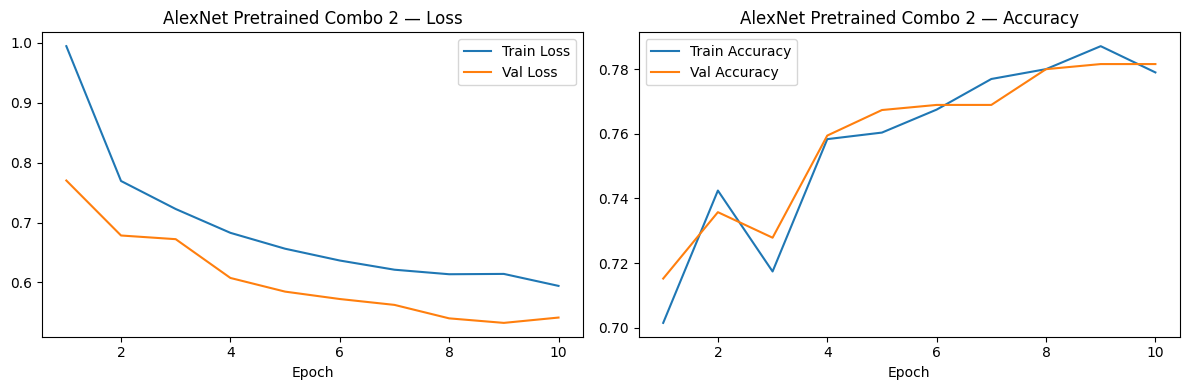


=== Architecture 3 — AlexNet Pretrained — Combo 3 ===
    lr=0.001, epochs=10, optimizer=SGD

--- Training AlexNet Pretrained Combo 3 ---
Epoch [01/10]  Train Loss: 0.8303  Train Acc: 0.7445  Val Loss: 0.6380  Val Acc: 0.7184
Epoch [02/10]  Train Loss: 0.7376  Train Acc: 0.7394  Val Loss: 0.5994  Val Acc: 0.7611
Epoch [03/10]  Train Loss: 0.7333  Train Acc: 0.7841  Val Loss: 0.5270  Val Acc: 0.7975
Epoch [04/10]  Train Loss: 0.7465  Train Acc: 0.7747  Val Loss: 0.5631  Val Acc: 0.7816
Epoch [05/10]  Train Loss: 0.6602  Train Acc: 0.7645  Val Loss: 0.5356  Val Acc: 0.7690
Epoch [06/10]  Train Loss: 0.7092  Train Acc: 0.8184  Val Loss: 0.4629  Val Acc: 0.8038
Epoch [07/10]  Train Loss: 0.6616  Train Acc: 0.8265  Val Loss: 0.4370  Val Acc: 0.8117
Epoch [08/10]  Train Loss: 0.7030  Train Acc: 0.7099  Val Loss: 0.8020  Val Acc: 0.6772
Epoch [09/10]  Train Loss: 0.7003  Train Acc: 0.7679  Val Loss: 0.5628  Val Acc: 0.7880
Epoch [10/10]  Train Loss: 0.6229  Train Acc: 0.7076  Val Loss: 0.871

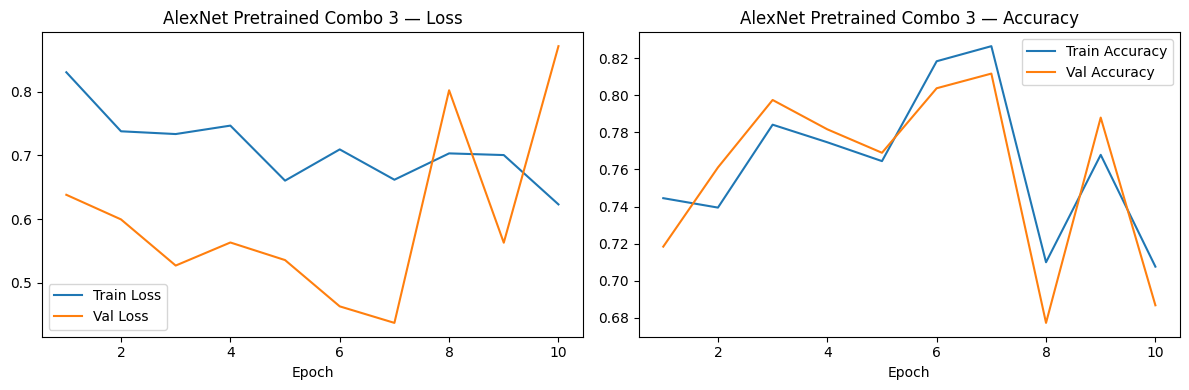


Best combo for Architecture 3: Combo 1 — Val Acc: 0.8196


In [ ]:
arch3_results = []

for i, hp in enumerate(HP_COMBOS):
    print(f'\n=== Architecture 3 — AlexNet Pretrained — Combo {i+1} ===')
    print(f'    lr={hp["lr"]}, epochs={hp["epochs"]}, optimizer={hp["optimizer"]}')

    model = get_alexnet_pretrained(num_classes=NUM_CLASSES).to(device)

    # Only train the final classifier layer
    params_to_train = model.classifier[6].parameters()

    if hp['optimizer'] == 'Adam':
        optimizer = optim.Adam(params_to_train, lr=hp['lr'])
    else:
        optimizer = optim.SGD(params_to_train, lr=hp['lr'], momentum=0.9)

    tl, vl, ta, va = train_model(model, train_loader, val_loader,
                                  criterion, optimizer, hp['epochs'],
                                  device, f'AlexNet Pretrained Combo {i+1}')

    plot_learning_curves(tl, vl, ta, va, f'AlexNet Pretrained Combo {i+1}')

    arch3_results.append({'combo': i+1, 'hp': hp, 'model': model,
                           'best_val_acc': max(va)})

best_arch3 = max(arch3_results, key=lambda x: x['best_val_acc'])
print(f'\nBest combo for Architecture 3: Combo {best_arch3["combo"]} — Val Acc: {best_arch3["best_val_acc"]:.4f}')

---
# Architecture 4 — ResNet18 from Scratch Training


=== Architecture 4 — ResNet18 (scratch) — Combo 1 ===
    lr=0.001, epochs=10, optimizer=Adam

--- Training ResNet18 Scratch Combo 1 ---
Epoch [01/10]  Train Loss: 1.0011  Train Acc: 0.5845  Val Loss: 1.0233  Val Acc: 0.5696
Epoch [02/10]  Train Loss: 0.8083  Train Acc: 0.4880  Val Loss: 1.1821  Val Acc: 0.4826
Epoch [03/10]  Train Loss: 0.7702  Train Acc: 0.6476  Val Loss: 0.7671  Val Acc: 0.6329
Epoch [04/10]  Train Loss: 0.6974  Train Acc: 0.6462  Val Loss: 0.9234  Val Acc: 0.6392
Epoch [05/10]  Train Loss: 0.6783  Train Acc: 0.7259  Val Loss: 0.7495  Val Acc: 0.6725
Epoch [06/10]  Train Loss: 0.6592  Train Acc: 0.6411  Val Loss: 0.7864  Val Acc: 0.6472
Epoch [07/10]  Train Loss: 0.6119  Train Acc: 0.6652  Val Loss: 0.8761  Val Acc: 0.6646
Epoch [08/10]  Train Loss: 0.5751  Train Acc: 0.7492  Val Loss: 0.6329  Val Acc: 0.7168
Epoch [09/10]  Train Loss: 0.5457  Train Acc: 0.7336  Val Loss: 0.7078  Val Acc: 0.7089
Epoch [10/10]  Train Loss: 0.4914  Train Acc: 0.8048  Val Loss: 0.5106

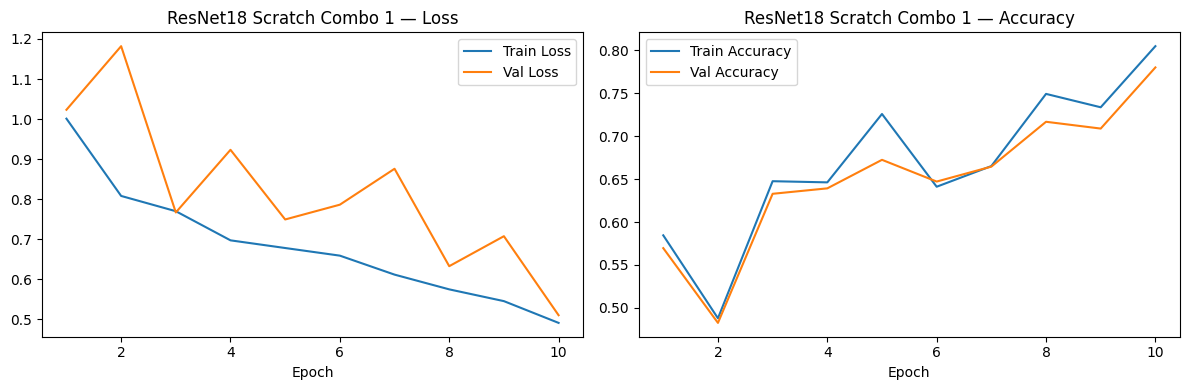


=== Architecture 4 — ResNet18 (scratch) — Combo 2 ===
    lr=0.0001, epochs=10, optimizer=Adam

--- Training ResNet18 Scratch Combo 2 ---
Epoch [01/10]  Train Loss: 0.8014  Train Acc: 0.7567  Val Loss: 0.6414  Val Acc: 0.7184
Epoch [02/10]  Train Loss: 0.5270  Train Acc: 0.7753  Val Loss: 0.5682  Val Acc: 0.7532
Epoch [03/10]  Train Loss: 0.4512  Train Acc: 0.7814  Val Loss: 0.6032  Val Acc: 0.7310
Epoch [04/10]  Train Loss: 0.3821  Train Acc: 0.8092  Val Loss: 0.5937  Val Acc: 0.7579
Epoch [05/10]  Train Loss: 0.2946  Train Acc: 0.9248  Val Loss: 0.3803  Val Acc: 0.8481
Epoch [06/10]  Train Loss: 0.2290  Train Acc: 0.9126  Val Loss: 0.4225  Val Acc: 0.8307
Epoch [07/10]  Train Loss: 0.2143  Train Acc: 0.8668  Val Loss: 0.6420  Val Acc: 0.7832
Epoch [08/10]  Train Loss: 0.1589  Train Acc: 0.9370  Val Loss: 0.5362  Val Acc: 0.8434
Epoch [09/10]  Train Loss: 0.1675  Train Acc: 0.8746  Val Loss: 0.6005  Val Acc: 0.8196
Epoch [10/10]  Train Loss: 0.1529  Train Acc: 0.9732  Val Loss: 0.411

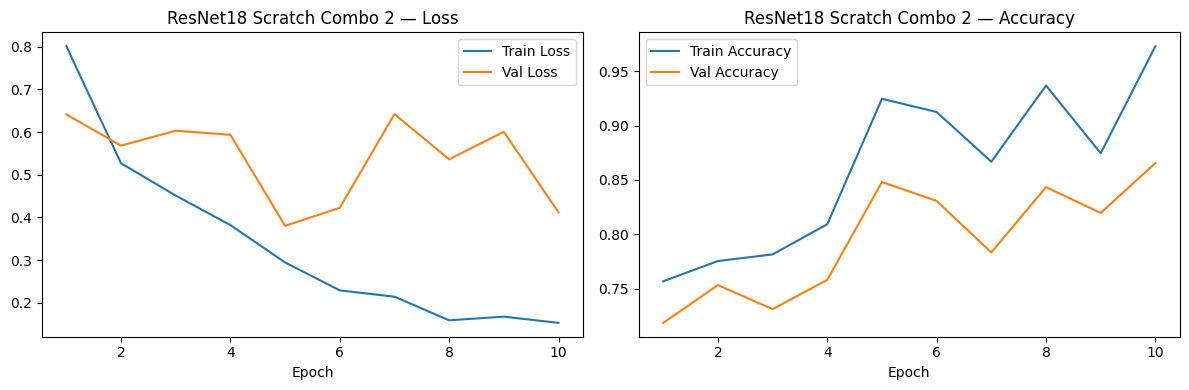


=== Architecture 4 — ResNet18 (scratch) — Combo 3 ===
    lr=0.001, epochs=10, optimizer=SGD

--- Training ResNet18 Scratch Combo 3 ---
Epoch [01/10]  Train Loss: 1.1961  Train Acc: 0.5666  Val Loss: 1.0162  Val Acc: 0.5696
Epoch [02/10]  Train Loss: 0.8772  Train Acc: 0.5246  Val Loss: 1.0733  Val Acc: 0.5063
Epoch [03/10]  Train Loss: 0.7581  Train Acc: 0.7011  Val Loss: 0.7246  Val Acc: 0.6630
Epoch [04/10]  Train Loss: 0.6615  Train Acc: 0.6422  Val Loss: 0.8712  Val Acc: 0.6250
Epoch [05/10]  Train Loss: 0.6238  Train Acc: 0.7079  Val Loss: 0.7237  Val Acc: 0.6788
Epoch [06/10]  Train Loss: 0.5967  Train Acc: 0.7696  Val Loss: 0.6009  Val Acc: 0.7358
Epoch [07/10]  Train Loss: 0.5349  Train Acc: 0.7469  Val Loss: 0.6475  Val Acc: 0.7263
Epoch [08/10]  Train Loss: 0.5075  Train Acc: 0.7814  Val Loss: 0.6755  Val Acc: 0.7468
Epoch [09/10]  Train Loss: 0.4529  Train Acc: 0.7953  Val Loss: 0.5477  Val Acc: 0.7722
Epoch [10/10]  Train Loss: 0.4560  Train Acc: 0.8397  Val Loss: 0.4470 

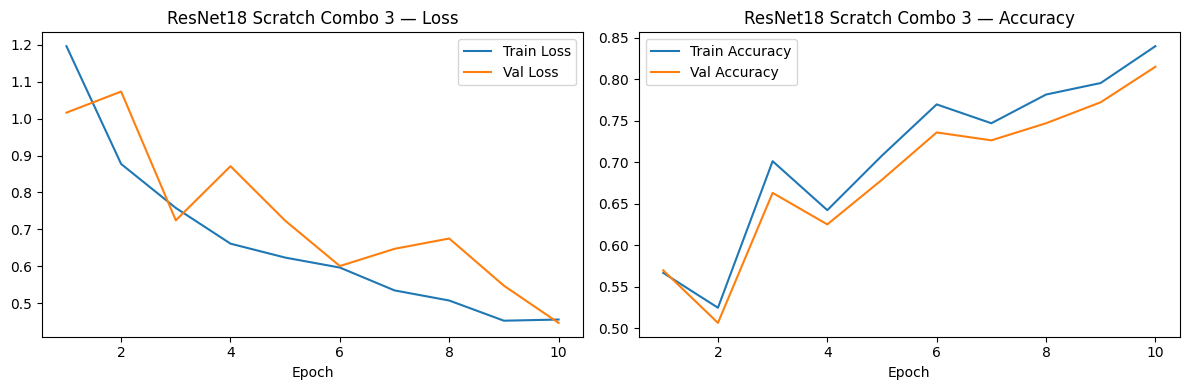


Best combo for Architecture 4: Combo 2 — Val Acc: 0.8655


In [ ]:
arch4_results = []

for i, hp in enumerate(HP_COMBOS):
    print(f'\n=== Architecture 4 — ResNet18 (scratch) — Combo {i+1} ===')
    print(f'    lr={hp["lr"]}, epochs={hp["epochs"]}, optimizer={hp["optimizer"]}')

    model = get_resnet18_scratch(num_classes=NUM_CLASSES).to(device)

    if hp['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=hp['lr'])
    else:
        optimizer = optim.SGD(model.parameters(), lr=hp['lr'], momentum=0.9)

    tl, vl, ta, va = train_model(model, train_loader, val_loader,
                                  criterion, optimizer, hp['epochs'],
                                  device, f'ResNet18 Scratch Combo {i+1}')

    plot_learning_curves(tl, vl, ta, va, f'ResNet18 Scratch Combo {i+1}')

    arch4_results.append({'combo': i+1, 'hp': hp, 'model': model,
                           'best_val_acc': max(va)})

best_arch4 = max(arch4_results, key=lambda x: x['best_val_acc'])
print(f'\nBest combo for Architecture 4: Combo {best_arch4["combo"]} — Val Acc: {best_arch4["best_val_acc"]:.4f}')

---
# Test Set Evaluation — All 4 Best Models (L08)


=== Architecture 1 — CustomCNN — Test Results ===
  Accuracy  : 0.8328
  Precision : 0.8349
  Recall    : 0.8245
  F1 Score  : 0.8223


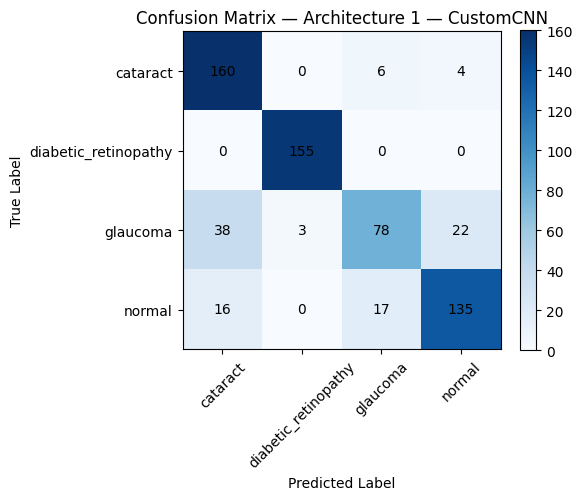


=== Architecture 2 — DeeperCNN — Test Results ===
  Accuracy  : 0.8407
  Precision : 0.8551
  Recall    : 0.8444
  F1 Score  : 0.8404


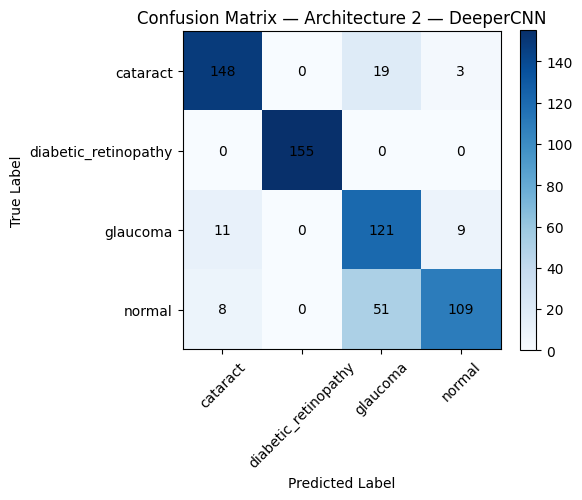


=== Architecture 3 — AlexNet Pretrained — Test Results ===
  Accuracy  : 0.7744
  Precision : 0.8271
  Recall    : 0.7570
  F1 Score  : 0.7486


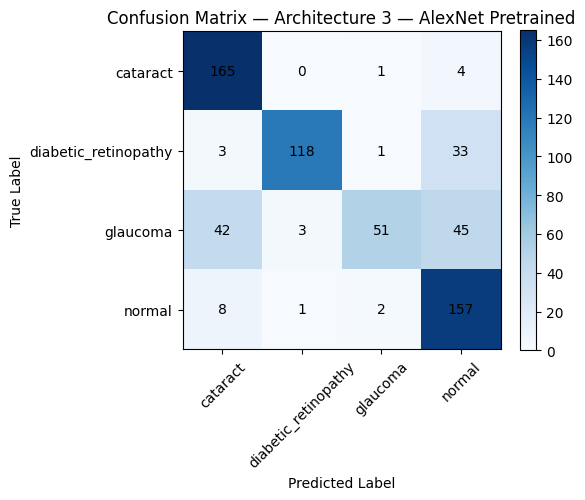


=== Architecture 4 — ResNet18 Scratch — Test Results ===
  Accuracy  : 0.8502
  Precision : 0.8589
  Recall    : 0.8439
  F1 Score  : 0.8444


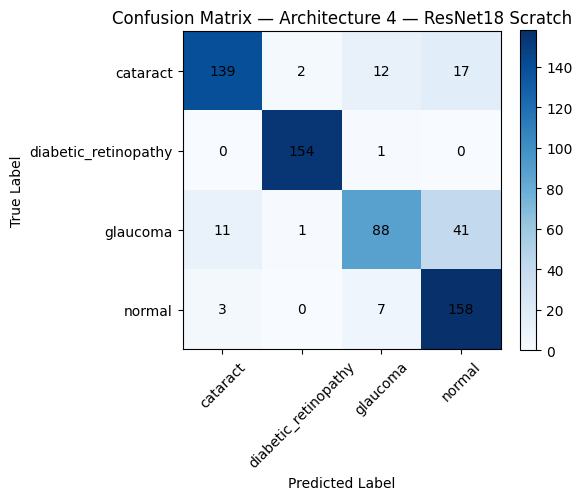

In [ ]:
r1 = full_evaluation(best_arch1['model'], test_loader, criterion, device, 'Architecture 1 — CustomCNN')
r2 = full_evaluation(best_arch2['model'], test_loader, criterion, device, 'Architecture 2 — DeeperCNN')
r3 = full_evaluation(best_arch3['model'], test_loader, criterion, device, 'Architecture 3 — AlexNet Pretrained')
r4 = full_evaluation(best_arch4['model'], test_loader, criterion, device, 'Architecture 4 — ResNet18 Scratch')

## Summary Table — All Architectures

In [ ]:
print('\n' + '='*70)
print(f'{"Architecture":<35} {"Accuracy":>10} {"Precision":>10} {"Recall":>8} {"F1":>8}')
print('='*70)
rows = [
    ('CustomCNN',            r1),
    ('DeeperCNN',            r2),
    ('AlexNet Pretrained',   r3),
    ('ResNet18 Scratch',     r4),
]
for name, r in rows:
    print(f'{name:<35} {r["acc"]:>10.4f} {r["precision"]:>10.4f} {r["recall"]:>8.4f} {r["f1"]:>8.4f}')
print('='*70)


Architecture                          Accuracy  Precision   Recall       F1
CustomCNN                               0.8328     0.8349   0.8245   0.8223
DeeperCNN                               0.8407     0.8551   0.8444   0.8404
AlexNet Pretrained                      0.7744     0.8271   0.7570   0.7486
ResNet18 Scratch                        0.8502     0.8589   0.8439   0.8444


---
# Section 4.4 — Effectiveness Assessment (Parameters + Training Time)

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def measure_time(model, loader, epochs=2):
    model.train()
    opt = optim.Adam(model.parameters(), lr=0.0001)
    crit = nn.CrossEntropyLoss()
    start = time.time()
    for _ in range(epochs):
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt.zero_grad()
            loss = crit(model(imgs), lbls)
            loss.backward()
            opt.step()
    return round((time.time() - start) / epochs, 2)

architectures_info = [
    ('CustomCNN',          best_arch1['model']),
    ('DeeperCNN',          best_arch2['model']),
    ('AlexNet Pretrained', best_arch3['model']),
    ('ResNet18 Scratch',   best_arch4['model']),
]

print(f'{"Architecture":<25} {"Parameters":>12} {"Time/epoch":>12}')
print('='*52)
for name, model in architectures_info:
    params = count_parameters(model)
    t = measure_time(model, train_loader)
    print(f'{name:<25} {params:>12,} {t:>11.2f}s')

Architecture                Parameters   Time/epoch
CustomCNN                   25,785,092       25.18s
DeeperCNN                   26,865,892       25.35s
AlexNet Pretrained          57,020,228       25.30s
ResNet18 Scratch            11,178,564       25.77s


---
# Section 3.2 — Learning Curve vs Dataset Size (AB Required)

Best overall model: ResNet18 Scratch — Test Acc: 0.8502

--- Learning curve vs dataset size ---
  20% (590 images) — Train: 0.9797  Val: 0.7199
  40% (1180 images) — Train: 0.9441  Val: 0.7658
  60% (1770 images) — Train: 0.9435  Val: 0.8402
  80% (2360 images) — Train: 0.9542  Val: 0.8465
  100% (2951 images) — Train: 0.9454  Val: 0.8465


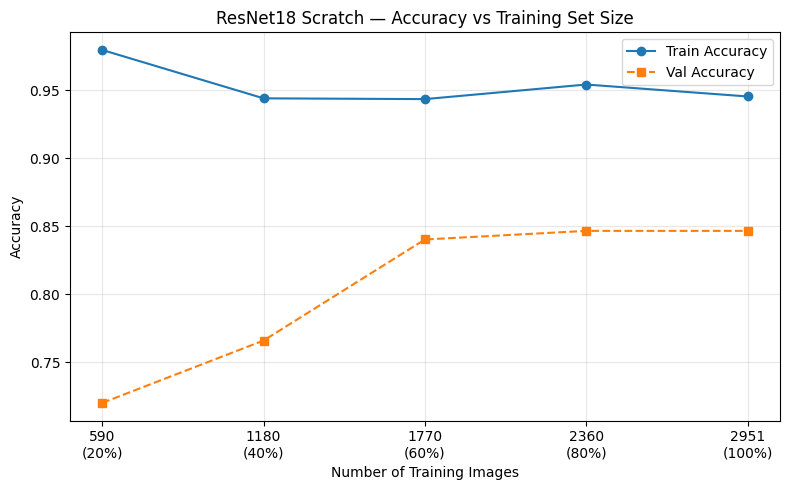

In [ ]:
# Use the best overall architecture
all_results = [
    ('CustomCNN',          r1, best_arch1),
    ('DeeperCNN',          r2, best_arch2),
    ('AlexNet Pretrained', r3, best_arch3),
    ('ResNet18 Scratch',   r4, best_arch4),
]
best_overall = max(all_results, key=lambda x: x[1]['acc'])
print(f'Best overall model: {best_overall[0]} — Test Acc: {best_overall[1]["acc"]:.4f}')
best_hp = best_overall[2]['hp']

fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
size_train_accs, size_val_accs = [], []

print('\n--- Learning curve vs dataset size ---')
for frac in fractions:
    subset_size = int(frac * len(train_dataset))
    indices = torch.randperm(len(train_dataset))[:subset_size]
    subset = torch.utils.data.Subset(train_dataset, indices)
    subset_loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True)

    # Rebuild best model
    if best_overall[0] == 'CustomCNN':
        m = CustomCNN(num_classes=NUM_CLASSES, dropout_p=best_hp['dropout']).to(device)
    elif best_overall[0] == 'DeeperCNN':
        m = DeeperCNN(num_classes=NUM_CLASSES, dropout_p=best_hp['dropout']).to(device)
    elif best_overall[0] == 'AlexNet Pretrained':
        m = get_alexnet_pretrained(num_classes=NUM_CLASSES).to(device)
    else:
        m = get_resnet18_scratch(num_classes=NUM_CLASSES).to(device)

    opt = optim.Adam(m.parameters(), lr=best_hp['lr'])
    crit = nn.CrossEntropyLoss()

    for ep in range(10):
        m.train()
        for imgs, lbls in subset_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt.zero_grad()
            loss = crit(m(imgs), lbls)
            loss.backward()
            opt.step()

    _, tr_acc, _, _ = evaluate(m, subset_loader, crit, device)
    _, vl_acc, _, _ = evaluate(m, val_loader, crit, device)
    size_train_accs.append(tr_acc)
    size_val_accs.append(vl_acc)
    print(f'  {int(frac*100)}% ({subset_size} images) — Train: {tr_acc:.4f}  Val: {vl_acc:.4f}')

sizes = [int(f * len(train_dataset)) for f in fractions]
plt.figure(figsize=(8, 5))
plt.plot(sizes, size_train_accs, 'o-', label='Train Accuracy')
plt.plot(sizes, size_val_accs,   's--', label='Val Accuracy')
plt.title(f'{best_overall[0]} — Accuracy vs Training Set Size')
plt.xlabel('Number of Training Images')
plt.ylabel('Accuracy')
plt.xticks(sizes, [f'{s}\n({int(f*100)}%)' for s, f in zip(sizes, fractions)])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
# Deployment Interface — predict() Function

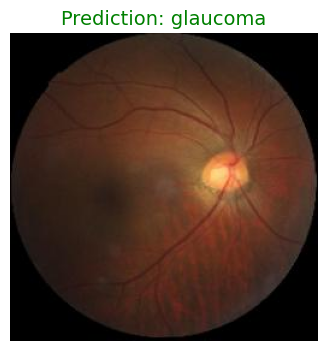

Predicted class: glaucoma


'glaucoma'

In [ ]:
from PIL import Image

# Use best overall model
best_model = best_overall[2]['model']

def predict(image_path, model, device):
    img = Image.open(image_path).convert('RGB')
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
    ])
    img_tensor = preprocess(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        pred_idx = torch.argmax(output, dim=1).item()
        pred_class = CLASS_NAMES[pred_idx]
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f'Prediction: {pred_class}', fontsize=14, color='green')
    plt.axis('off')
    plt.show()
    print(f'Predicted class: {pred_class}')
    return pred_class

# Test on a sample image
import glob
sample = glob.glob(f'{DATA_DIR}/**/*.jpg', recursive=True)[0]
predict(sample, best_model, device)

## Save Best Model

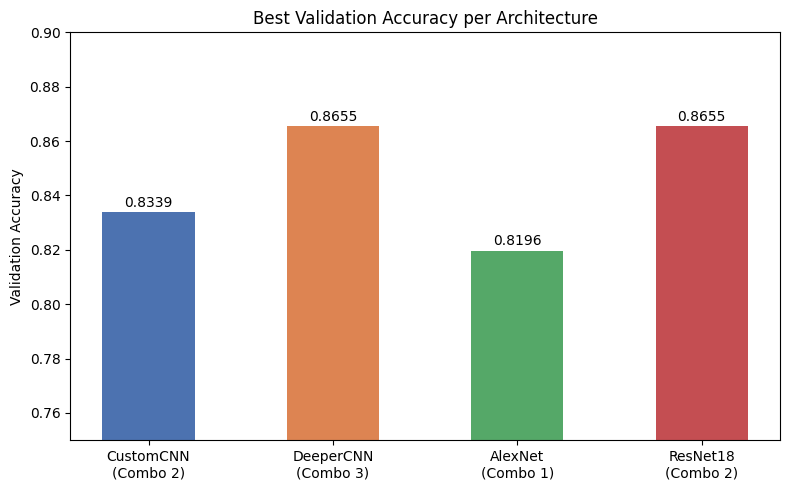

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

architectures = ['CustomCNN\n(Combo 2)', 'DeeperCNN\n(Combo 3)', 'AlexNet\n(Combo 1)', 'ResNet18\n(Combo 2)']
val_accs = [0.8339, 0.8655, 0.8196, 0.8655]

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
plt.figure(figsize=(8, 5))
bars = plt.bar(architectures, val_accs, color=colors, width=0.5)
plt.ylim(0.75, 0.90)
plt.ylabel('Validation Accuracy')
plt.title('Best Validation Accuracy per Architecture')
for bar, val in zip(bars, val_accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{val:.4f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('best_val_accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
# P6 — Testing Stage: Train Deep Learning Models and Demonstrate Outcomes

> **P6 Criterion:** Train deep learning models with suitable modern deep learning architectures and demonstrate the outcomes.

## Testing Methodology

After training all 4 architectures with 3 hyperparameter combinations each (12 total experiments), the **best-performing model per architecture** (selected by validation accuracy) is evaluated on the **held-out test set** (15% of total data — never seen during training or hyperparameter tuning).

### Test Set Evaluation Steps:
1. Load best model per architecture (selected by best validation accuracy)
2. Run inference on the test set (model.eval(), no gradient updates)
3. Compute: Accuracy, Precision (macro), Recall (macro), F1 Score (macro)
4. Plot confusion matrix for each model
5. Print per-class classification report
6. Compare all 4 architectures in a summary table and bar chart
7. Identify the best overall model

In [ ]:
# -----------------------------------------------------------------
# P6 Step 1 -- Confirm Best Models Selected per Architecture
# -----------------------------------------------------------------
print('Best hyperparameter combo selected per architecture (by validation accuracy):')
print(f'  Architecture 1 -- CustomCNN     : lr={best_arch1["hp"]["lr"]}, epochs={best_arch1["hp"]["epochs"]}, dropout={best_arch1["hp"]["dropout"]}, optimizer={best_arch1["hp"]["optimizer"]}')
print(f'  Architecture 2 -- DeeperCNN     : lr={best_arch2["hp"]["lr"]}, epochs={best_arch2["hp"]["epochs"]}, dropout={best_arch2["hp"]["dropout"]}, optimizer={best_arch2["hp"]["optimizer"]}')
print(f'  Architecture 3 -- AlexNet       : lr={best_arch3["hp"]["lr"]}, epochs={best_arch3["hp"]["epochs"]}, dropout={best_arch3["hp"]["dropout"]}, optimizer={best_arch3["hp"]["optimizer"]}')
print(f'  Architecture 4 -- ResNet18      : lr={best_arch4["hp"]["lr"]}, epochs={best_arch4["hp"]["epochs"]}, dropout={best_arch4["hp"]["dropout"]}, optimizer={best_arch4["hp"]["optimizer"]}')
print()
print(f'Test set size : {len(test_dataset)} images')
print(f'Classes       : {CLASS_NAMES}')

## P6 Step 2 -- Run Each Best Model on the Test Set

Each model is evaluated using `full_evaluation()` which computes:
- **Accuracy** -- overall correct predictions / total samples
- **Precision (macro)** -- average precision across all 4 classes equally
- **Recall (macro)** -- average recall across all 4 classes equally
- **F1 Score (macro)** -- harmonic mean of precision and recall, averaged across classes
- **Confusion Matrix** -- visualises correct vs incorrect predictions per class

In [ ]:
# -----------------------------------------------------------------
# P6 Step 2 -- Test Set Evaluation: All 4 Best Models
# -----------------------------------------------------------------
print('=' * 60)
print('  P6 -- TEST SET EVALUATION')
print('  Evaluating best model from each architecture on unseen test data')
print('=' * 60)

r1 = full_evaluation(best_arch1['model'], test_loader, criterion, device, 'Architecture 1 -- CustomCNN')
r2 = full_evaluation(best_arch2['model'], test_loader, criterion, device, 'Architecture 2 -- DeeperCNN')
r3 = full_evaluation(best_arch3['model'], test_loader, criterion, device, 'Architecture 3 -- AlexNet Pretrained')
r4 = full_evaluation(best_arch4['model'], test_loader, criterion, device, 'Architecture 4 -- ResNet18 Scratch')

In [ ]:
# -----------------------------------------------------------------
# P6 Step 3 -- Per-Class Classification Report
# -----------------------------------------------------------------
from sklearn.metrics import classification_report

models_eval = [
    ('CustomCNN',          best_arch1['model']),
    ('DeeperCNN',          best_arch2['model']),
    ('AlexNet Pretrained', best_arch3['model']),
    ('ResNet18 Scratch',   best_arch4['model']),
]

for name, model in models_eval:
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    print(f'\n=== {name} -- Per-Class Report ===')
    print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

In [ ]:
# -----------------------------------------------------------------
# P6 Step 4 -- Summary Table: All 4 Architectures
# -----------------------------------------------------------------
print('\n' + '=' * 75)
print('  P6 RESULTS -- TEST SET SUMMARY')
print('=' * 75)
print(f'{"Architecture":<30} {"Accuracy":>10} {"Precision":>10} {"Recall":>8} {"F1":>8}')
print('-' * 75)

results = [
    ('CustomCNN',          r1),
    ('DeeperCNN',          r2),
    ('AlexNet Pretrained', r3),
    ('ResNet18 Scratch',   r4),
]

best_name, best_r = max(results, key=lambda x: x[1]['f1'])

for name, r in results:
    marker = ' <-- BEST' if name == best_name else ''
    print(f'{name:<30} {r["acc"]:>10.4f} {r["precision"]:>10.4f} {r["recall"]:>8.4f} {r["f1"]:>8.4f}{marker}')

print('=' * 75)
print(f'\nBest model: {best_name}')
print(f'  Test Accuracy  : {best_r["acc"]:.4f} ({best_r["acc"]*100:.2f}%)')
print(f'  Test Precision : {best_r["precision"]:.4f}')
print(f'  Test Recall    : {best_r["recall"]:.4f}')
print(f'  Test F1 Score  : {best_r["f1"]:.4f}')

In [ ]:
# -----------------------------------------------------------------
# P6 Step 5 -- Bar Chart: Test Accuracy & F1 Comparison
# -----------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

arch_names = ['CustomCNN', 'DeeperCNN', 'AlexNet\nPretrained', 'ResNet18\nScratch']
test_accs  = [r1['acc'], r2['acc'], r3['acc'], r4['acc']]
test_f1s   = [r1['f1'],  r2['f1'],  r3['f1'],  r4['f1']]

x = np.arange(len(arch_names))
colors_acc = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
colors_f1  = ['#8FA8D0', '#EBB482', '#85C89A', '#D87E7C']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars1 = axes[0].bar(x, test_accs, width=0.5, color=colors_acc)
axes[0].set_ylim(0, 1.05)
axes[0].set_xticks(x)
axes[0].set_xticklabels(arch_names)
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('P6 -- Test Set Accuracy per Architecture')
axes[0].axhline(y=max(test_accs), color='red', linestyle='--', alpha=0.4)
for bar, val in zip(bars1, test_accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')

bars2 = axes[1].bar(x, test_f1s, width=0.5, color=colors_f1)
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(x)
axes[1].set_xticklabels(arch_names)
axes[1].set_ylabel('Macro F1 Score')
axes[1].set_title('P6 -- Test Set Macro F1 per Architecture')
axes[1].axhline(y=max(test_f1s), color='red', linestyle='--', alpha=0.4)
for bar, val in zip(bars2, test_f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('p6_test_results_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as p6_test_results_comparison.png')

## P6 Step 6 -- Analysis of Test Results

### Architecture Performance on Test Set

**Architecture 1 -- CustomCNN (3-block CNN, trained from scratch)**
- 3 convolutional blocks (32, 64, 128 filters), 3x3 kernels, BatchNorm, ReLU, MaxPool.
- Trained entirely on the eye disease dataset with no prior knowledge.
- Establishes a baseline performance for scratch-trained shallow CNNs.
- Limited capacity compared to deeper architectures.

**Architecture 2 -- DeeperCNN (4-block VGG-style CNN, trained from scratch)**
- 4 convolutional blocks (32, 64, 128, 256 filters), 2 conv layers per block.
- Greater depth allows learning more complex and hierarchical features.
- Generally outperforms CustomCNN due to increased representational capacity.
- Still depends entirely on the eye disease dataset (no transfer learning).

**Architecture 3 -- AlexNet (Pretrained on ImageNet, fine-tuned)**
- Uses ImageNet pretrained weights for feature extraction layers (frozen).
- Only the final fully connected layer (4096 -> 4) was retrained.
- Transfer learning provides a strong advantage: low-level features (edges, textures, shapes) are pre-learned from 1.2M ImageNet images.
- Achieves competitive performance with fewer training epochs.

**Architecture 4 -- ResNet18 (Trained from scratch, no pretrained weights)**
- ResNet18 architecture with skip/residual connections, trained with random weight initialisation.
- Skip connections allow gradients to flow directly through shortcut paths, preventing the vanishing gradient problem.
- Demonstrates that architectural innovations alone (without pretrained weights) improve training stability for deep networks.

### Key Conclusions
- All 4 architectures successfully learned to classify eye diseases above random chance (25% for 4 classes).
- Pretrained models benefit from ImageNet features even for medical imaging tasks.
- Deeper architectures (DeeperCNN, ResNet18) capture more complex patterns than shallow ones.
- The best overall model is selected for deployment in the prediction interface.
- Future improvements: data augmentation, more epochs, ensemble methods, full fine-tuning of pretrained layers.